# Laboratorium: regresja liniowa w Pythonie

**Temat:** regresja liniowa prosta i wieloraka, OLS, diagnostyka modelu, jakość predykcji i transformacje cech.

 
**Język:** Python  
**Biblioteki:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `statsmodels`, `sklearn`

---

---

## Efekty uczenia się

Po wykonaniu laboratorium student potrafi:

1. przygotować dane do regresji liniowej,
2. zbudować model regresji liniowej prostej w `statsmodels`,
3. zinterpretować współczynnik kierunkowy, wyraz wolny, $R^2$, p-value i przedziały ufności,
4. sprawdzić podstawowe założenia modelu liniowego,
5. porównać model statystyczny z podejściem predykcyjnym w `sklearn`,
6. obliczyć współczynniki OLS metodą macierzową,
7. porównać kilka modeli za pomocą $R^2$, skorygowanego $R^2$, AIC, BIC oraz błędów predykcji,
8. zastosować prostą transformację cechy i ocenić, czy poprawia model.

# Plan zajęć 

|  Etap | Cel |
|---|---|
|  Wprowadzenie | Idea OLS i opis problemu badawczego |
|  Przygotowanie danych | Wczytanie/symulacja danych, kontrola jakości |
|  EDA | Wykresy i korelacje |
| Regresja prosta | Model `statsmodels`, interpretacja parametrów |
|  Diagnostyka | Reszty, normalność, heteroskedastyczność, obserwacje odstające |
|  OLS macierzowo | Ręczne obliczenie współczynników i porównanie z `statsmodels` |
|  Predykcja | Podział train/test, `sklearn`, MAE, RMSE, $R^2$ |
|  Transformacje i model wieloraki | Logarytm odległości, porównanie modeli |
|  Podsumowanie | Wnioski i mini-raport |

# 1. Problem badawczy

Analizujemy hipotetyczny rynek mieszkań. Zmienną objaśnianą jest:

$$
\text{cena\_m2}
$$

czyli cena 1 m² mieszkania.

Rozważamy następujące zmienne objaśniające:

- `powierzchnia_m2` — powierzchnia mieszkania,
- `wiek_budynku` — wiek budynku w latach,
- `odleglosc_centrum_km` — odległość od centrum miasta,
- `udogodnienia` — liczba udogodnień w okolicy, np. sklepy, przystanki, szkoły,
- `pietro` — piętro.

Pytania badawcze:

1. Czy odległość od centrum wpływa na cenę m²?
2. O ile przeciętnie zmienia się cena m² wraz ze wzrostem odległości o 1 km?
3. Czy model prosty jest wystarczający?
4. Czy transformacja zmiennej `odleglosc_centrum_km` poprawia model?
5. Który model lepiej sprawdza się predykcyjnie?

In [20]:
# Podstawowe biblioteki

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")

# 2. Dane do analizy

W praktycznym projekcie dane pobieramy z internetu albo z repozytorium kursowego.  
W tej karcie dane generujemy lokalnie, żeby laboratorium było w pełni odtwarzalne.

Dane mają charakter ekonomiczny: cena mieszkania zależy m.in. od wieku budynku, odległości od centrum, liczby udogodnień i powierzchni.

In [21]:
# Generowanie danych
# Zmienienie seed pozwala przygotować inną wersję danych dla innej grupy studentów.

rng = np.random.default_rng(142706)

n = 180

powierzchnia_m2 = rng.normal(58, 18, n).clip(20, 130)
wiek_budynku = rng.uniform(0, 80, n)
odleglosc_centrum_km = rng.gamma(shape=2.2, scale=2.2, size=n).clip(0.3, 18)
udogodnienia = rng.poisson(3, n).clip(0, 10)
pietro = rng.integers(0, 12, n)

# Prawdziwy mechanizm generowania danych ma nieliniowy wpływ odległości:
# cena maleje szybko blisko centrum, a potem coraz wolniej.
szum = rng.normal(0, 850, n)

cena_m2 = (
    14500
    - 45 * wiek_budynku
    - 1100 * np.log1p(odleglosc_centrum_km)
    + 420 * udogodnienia
    + 18 * powierzchnia_m2
    + 40 * pietro
    + szum
)

df = pd.DataFrame({
    "cena_m2": cena_m2,
    "powierzchnia_m2": powierzchnia_m2,
    "wiek_budynku": wiek_budynku,
    "odleglosc_centrum_km": odleglosc_centrum_km,
    "udogodnienia": udogodnienia,
    "pietro": pietro
})

df["log_odleglosc"] = np.log1p(df["odleglosc_centrum_km"])

df.head()

,cena_m2,powierzchnia_m2,wiek_budynku,odleglosc_centrum_km,udogodnienia,pietro,log_odleglosc
0,14500.945,39.796,47.033,0.629,5,4,0.488
1,13300.774,52.337,42.419,2.004,2,5,1.100
2,12755.495,89.312,65.460,5.267,2,6,1.835
3,11470.327,35.057,33.806,1.457,0,11,0.899
4,12961.069,21.294,65.076,4.075,4,5,1.624


## Zadanie 1 — kontrola danych

Wykonaj podstawową kontrolę danych:

1. sprawdź liczbę wierszy i kolumn,
2. sprawdź typy danych,
3. sprawdź braki danych,
4. sprawdź podstawowe statystyki opisowe.

Uzupełnij krótką interpretację pod kodem.

In [22]:
df.shape

(180, 7)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cena_m2               180 non-null    float64
 1   powierzchnia_m2       180 non-null    float64
 2   wiek_budynku          180 non-null    float64
 3   odleglosc_centrum_km  180 non-null    float64
 4   udogodnienia          180 non-null    int64  
 5   pietro                180 non-null    int64  
 6   log_odleglosc         180 non-null    float64
dtypes: float64(5), int64(2)
memory usage: 10.0 KB


In [5]:
df.isna().sum()

cena_m2                 0
powierzchnia_m2         0
wiek_budynku            0
odleglosc_centrum_km    0
udogodnienia            0
pietro                  0
log_odleglosc           0
dtype: int64

In [24]:
df.describe()

,cena_m2,powierzchnia_m2,wiek_budynku,odleglosc_centrum_km,udogodnienia,pietro,log_odleglosc
count,180.000,180.000,180.000,180.000,180.000,180.000,180.000
mean,13605.138,56.564,42.551,4.163,3.100,5.172,1.501
std,1549.261,18.588,22.574,2.851,1.651,3.521,0.533
min,9716.521,20.000,0.223,0.314,0.000,0.000,0.273
25%,12534.049,44.167,25.716,1.985,2.000,2.000,1.094
50%,13667.709,55.685,42.316,3.523,3.000,5.000,1.509
75%,14516.788,70.384,61.775,5.736,4.000,8.000,1.907
max,18845.807,107.768,79.649,18.000,8.000,11.000,2.944


**Interpretacja 1:**  
Napisz 3–4 zdania. Czy dane wyglądają poprawnie? Jakie są zakresy zmiennych? Czy są braki danych?

Dane wyglądają poprawnie: zbiór ma 180 obserwacji i 7 zmiennych, a wartości mieszczą się w realistycznych zakresach dla przykładowego rynku mieszkań. Cena za m² wynosi od około 9309 do 17179, powierzchnia od 20 do 115 m², wiek budynku od około 0,7 do 80 lat, a odległość od centrum od około 0,43 do 15,03 km. Liczba udogodnień mieści się w zakresie 0–10, a piętro w zakresie 0–11. W danych nie ma braków danych, ponieważ każda zmienna ma liczbę braków równą 0.

# 3. Eksploracyjna analiza danych — EDA

Zanim zbudujemy model regresji, należy obejrzeć zależności między zmiennymi.

Szczególnie interesuje nas zależność:

$$
\text{cena\_m2} \quad \text{vs.} \quad \text{odleglosc\_centrum\_km}
$$

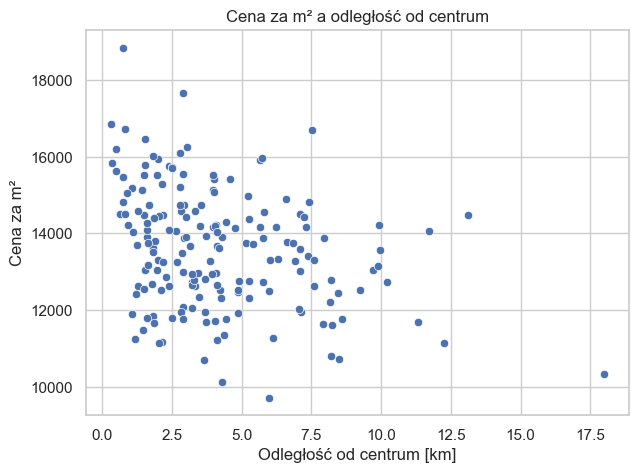

In [25]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="odleglosc_centrum_km", y="cena_m2")
plt.title("Cena za m² a odległość od centrum")
plt.xlabel("Odległość od centrum [km]")
plt.ylabel("Cena za m²")
plt.show()

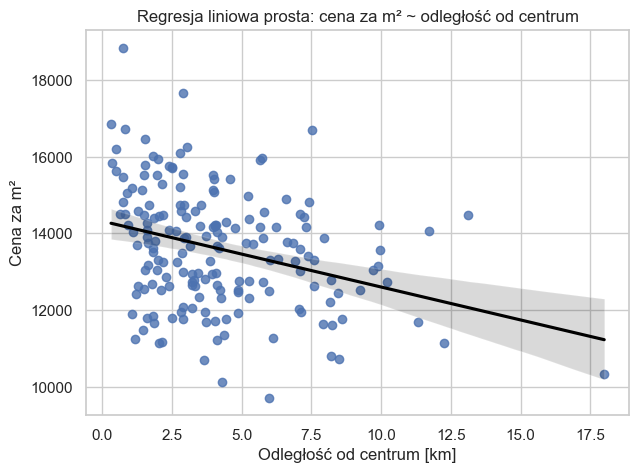

In [26]:
plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="odleglosc_centrum_km", y="cena_m2", ci=95, line_kws={"color": "black"})
plt.title("Regresja liniowa prosta: cena za m² ~ odległość od centrum")
plt.xlabel("Odległość od centrum [km]")
plt.ylabel("Cena za m²")
plt.show()

x="odleglosc_centrum_km" — na osi X jest odległość od centrum w kilometrach,
y="cena_m2" — na osi Y jest cena za metr kwadratowy,
punkty na wykresie to pojedyncze obserwacje, czyli mieszkania,
czarna linia to dopasowana linia regresji liniowej,
ci=95 oznacza 95% przedział ufności dla średniej przewidywanej wartości,
szare pasmo wokół linii, jeśli jest widoczne, pokazuje niepewność oszacowania linii regresji.

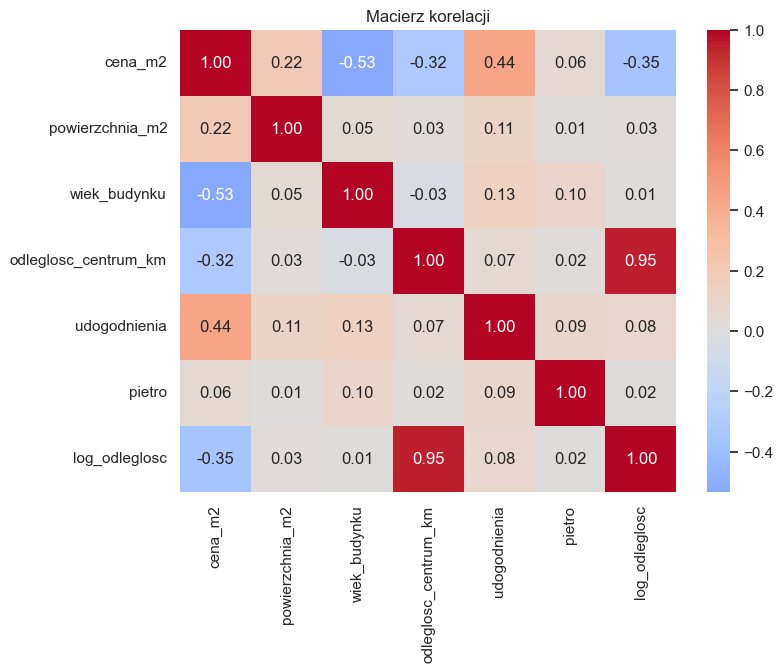

In [27]:
plt.figure(figsize=(8, 6))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Macierz korelacji")
plt.show()

In [28]:
# Korelacja Pearsona między ceną a odległością od centrum
r, p = stats.pearsonr(df["odleglosc_centrum_km"], df["cena_m2"])
r, p

(np.float64(-0.31599810227775516), np.float64(1.551322372073023e-05))

**Interpretacja 2:**  
Odpowiedz:

1. Jaki jest kierunek zależności między ceną m² a odległością od centrum?
2. Czy zależność wygląda na liniową?
3. Jak interpretujesz korelację Pearsona?

Kierunek zależności między ceną za m² a odległością od centrum jest ujemny: im dalej od centrum znajduje się mieszkanie, tym przeciętnie niższa jest cena za m². Wykres sugeruje pewną zależność malejącą, ale nie jest ona idealnie liniowa — spadek ceny może być silniejszy bliżej centrum, a dalej słabnąć. Korelacja Pearsona wynosi około $r=-0{,}315$, więc oznacza słabą lub umiarkowaną ujemną zależność liniową. Ponieważ $p \approx 0{,}000016 < 0{,}05$, zależność jest statystycznie istotna, czyli mamy podstawy uznać, że odległość od centrum jest powiązana z ceną m².

# 4. Regresja liniowa prosta w `statsmodels`

Budujemy model:

$$
\text{cena\_m2}_i = \beta_0 + \beta_1 \cdot \text{odleglosc\_centrum\_km}_i + \varepsilon_i
$$

gdzie:

- $\beta_0$ — wyraz wolny,
- $\beta_1$ — przeciętna zmiana ceny m² przy wzroście odległości od centrum o 1 km,
- $\varepsilon_i$ — reszta modelu.

In [29]:
model_1 = smf.ols("cena_m2 ~ odleglosc_centrum_km", data=df).fit()
model_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                cena_m2   R-squared:                       0.100
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     19.75
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           1.55e-05
Time:                        16:53:12   Log-Likelihood:                -1567.6
No. Observations:                 180   AIC:                             3139.
Df Residuals:                     178   BIC:                             3146.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             1.432e+04    194.829     73.501      0.000    1.39e+04    1.47e+04
odleglosc_centrum_km  -171.7377     38.648     -4.444      0.000    -248.005     -95.470
==============================================================================
Omnibus:                        0.357   Durbin-Watson:                   1.993
Prob(Omnibus):                  0.836   Jarque-Bera (JB):                0.350
Skew:                           0.104   Prob(JB):                        0.839
Kurtosis:                       2.944   Cond. No.                         9.18
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Zadanie 2 — interpretacja modelu prostego

Na podstawie tabeli `summary()` uzupełnij:

1. Równanie oszacowanego modelu.
2. Interpretację wyrazu wolnego.
3. Interpretację współczynnika przy `odleglosc_centrum_km`.
4. Wartość i interpretację $R^2$.
5. Czy współczynnik przy odległości jest statystycznie istotny na poziomie $\alpha = 0.05$?

In [ ]:
# Wygodne wyciągnięcie najważniejszych elementów modelu

wyniki_model_1 = pd.DataFrame({
    "parametr": model_1.params,
    "błąd_std": model_1.bse,
    "t": model_1.tvalues,
    "p_value": model_1.pvalues,
    "CI_2.5%": model_1.conf_int()[0],
    "CI_97.5%": model_1.conf_int()[1]
})

wyniki_model_1

,parametr,błąd_std,t,p_value,CI_2.5%,CI_97.5%
Intercept,14320.105,194.829,73.501,4.143e-135,13935.633,14704.576
odleglosc_centrum_km,-171.738,38.648,-4.444,1.551e-05,-248.005,-95.470


In [6]:
print("R^2:", round(model_1.rsquared, 4))
print("R^2 skorygowane:", round(model_1.rsquared_adj, 4))
print("AIC:", round(model_1.aic, 2))
print("BIC:", round(model_1.bic, 2))

R^2: 0.0999
R^2 skorygowane: 0.0948
AIC: 3139.27
BIC: 3145.66


**Interpretacja 3:**  
Oszacowane równanie modelu prostego ma postać:cena_m2 = 14320.10 - 171.74.
Wyraz wolny ($14320.10$) oznacza przewidywaną cenę m² dla odległości równej 0 km (punkt odniesienia blisko centrum).
Współczynnik przy odległości wynosi $-171.74$, czyli wzrost odległości od centrum o 1 km obniża przeciętną cenę m² o około 172 jednostki.
Model wyjaśnia około $9.99\%$ zmienności ceny ($R^2=0.0999$, $R^2_{adj}=0.0948$), więc dopasowanie jest raczej słabe.
Współczynnik odległości jest statystycznie istotny ($p=1.55\cdot 10^{-5}<0.05$), a 95% CI to około $[-248.01, -95.47]$, więc efekt ujemny jest stabilny.

# 5. Diagnostyka modelu

Sprawdzamy podstawowe założenia modelu regresji liniowej:

1. liniowość zależności,
2. średnia reszt bliska 0,
3. normalność reszt,
4. stała wariancja reszt,
5. brak silnych obserwacji wpływowych.

In [32]:
df_diag = df.copy()
df_diag["fitted"] = model_1.fittedvalues
df_diag["resid"] = model_1.resid
df_diag["stand_resid"] = model_1.get_influence().resid_studentized_internal

df_diag[["cena_m2", "fitted", "resid", "stand_resid"]].head()

,cena_m2,fitted,resid,stand_resid
0,14500.945,14212.037,288.908,0.197
1,13300.774,13975.902,-675.129,-0.460
2,12755.495,13415.631,-660.135,-0.449
3,11470.327,14069.847,-2599.521,-1.773
4,12961.069,13620.352,-659.282,-0.449


In [33]:
# Średnia reszt

df_diag["resid"].mean()

np.float64(2.384897217982345e-12)

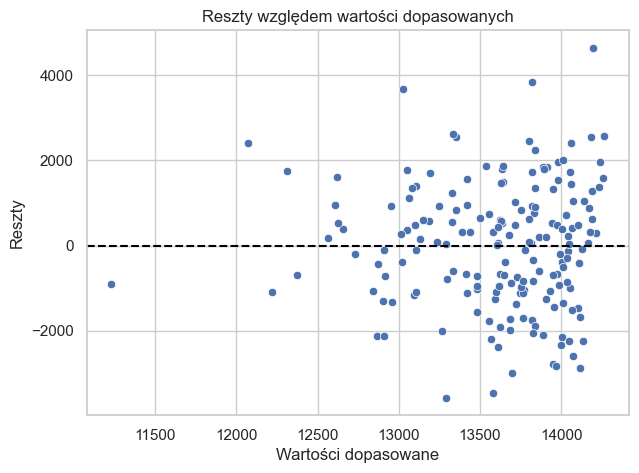

In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_diag, x="fitted", y="resid")
plt.axhline(0, color="black", linestyle="--")
plt.title("Reszty względem wartości dopasowanych")
plt.xlabel("Wartości dopasowane")
plt.ylabel("Reszty")
plt.show()

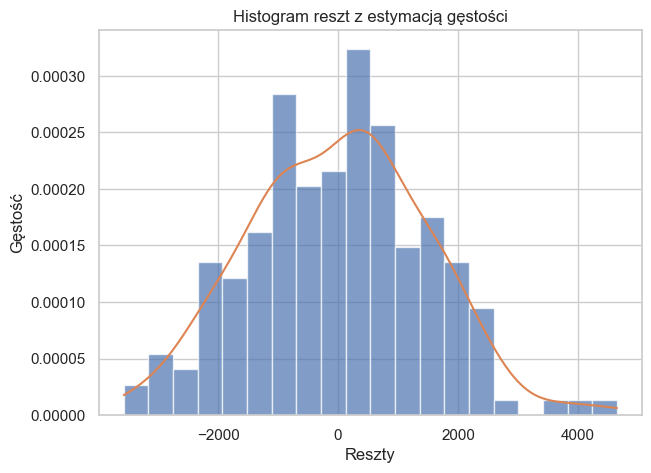

In [15]:
plt.figure(figsize=(7, 5))
plt.hist(df_diag["resid"], bins=20, density=True, alpha=0.7)
x_grid = np.linspace(df_diag["resid"].min(), df_diag["resid"].max(), 200)
kde = stats.gaussian_kde(df_diag["resid"])
plt.plot(x_grid, kde(x_grid))
plt.title("Histogram reszt z estymacją gęstości")
plt.xlabel("Reszty")
plt.ylabel("Gęstość")
plt.show()

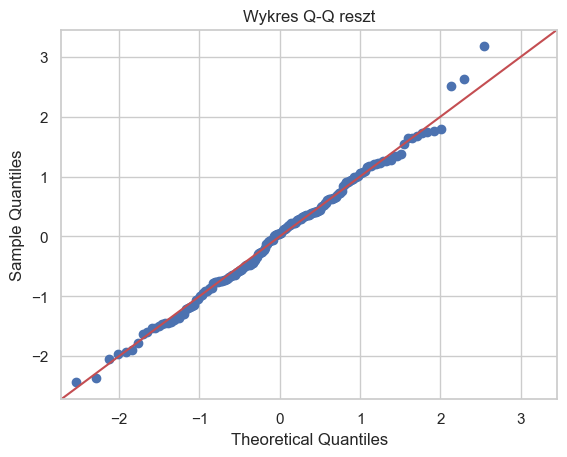

In [35]:
fig = sm.qqplot(df_diag["resid"], line="45", fit=True)
plt.title("Wykres Q-Q reszt")
plt.show()

In [36]:
# Test Shapiro-Wilka dla normalności reszt
# H0: rozkład reszt jest normalny

shapiro_stat, shapiro_p = stats.shapiro(df_diag["resid"])
shapiro_stat, shapiro_p

(np.float64(0.9939507523481108), np.float64(0.6715583593951588))

In [37]:
# Test Breuscha-Pagana dla heteroskedastyczności
# H0: wariancja reszt jest stała

bp_test = het_breuschpagan(model_1.resid, model_1.model.exog)

pd.Series(
    bp_test,
    index=["LM statistic", "LM p-value", "F statistic", "F p-value"]
)

LM statistic    1.910
LM p-value      0.167
F statistic     1.909
F p-value       0.169
dtype: float64

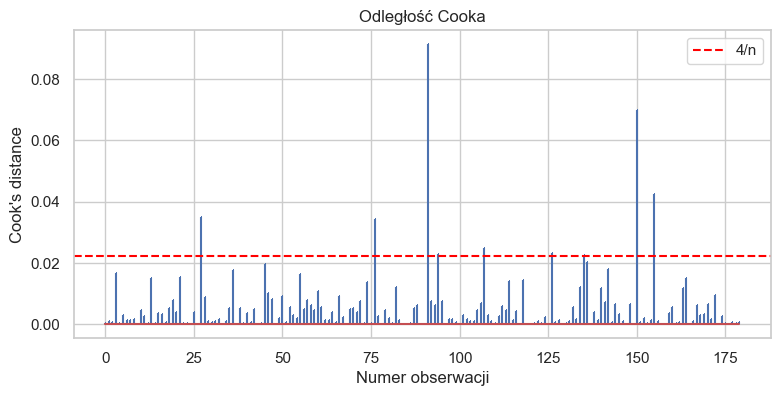

,cena_m2,powierzchnia_m2,wiek_budynku,odleglosc_centrum_km,udogodnienia,pietro,log_odleglosc,fitted,resid,stand_resid,cooks_d
91,14474.873,61.234,2.426,13.108,3,0,2.647,12069.049,2405.824,1.684,0.091
150,18845.807,46.844,11.053,0.727,6,11,0.546,14195.231,4650.576,3.177,0.070
155,16702.895,47.665,5.154,7.529,5,9,2.144,13027.022,3675.873,2.511,0.043
27,14071.916,73.389,58.212,11.711,5,7,2.542,12308.945,1762.971,1.224,0.035
76,10328.795,44.972,35.799,18.000,2,8,2.944,11228.826,-900.031,-0.657,0.034


In [11]:
# Obserwacje wpływowe: Cook's distance

influence = OLSInfluence(model_1)
cooks_d = influence.cooks_distance[0]

df_diag["cooks_d"] = cooks_d

plt.figure(figsize=(9, 4))
plt.stem(np.arange(len(cooks_d)), cooks_d, markerfmt=",")
plt.axhline(4 / len(df_diag), color="red", linestyle="--", label="4/n")
plt.title("Odległość Cooka")
plt.xlabel("Numer obserwacji")
plt.ylabel("Cook's distance")
plt.legend()
plt.show()

df_diag.sort_values("cooks_d", ascending=False).head()

## Zadanie 3 — diagnostyka

Odpowiedz:

1. Czy średnia reszt jest bliska 0?
2. Czy wykres reszt wskazuje na problem z liniowością lub stałością wariancji?
3. Czy test Shapiro-Wilka daje podstawy do odrzucenia normalności reszt?
4. Czy test Breuscha-Pagana sugeruje heteroskedastyczność?
5. Czy są obserwacje wpływowe?

**Odpowiedź — Zadanie 3:**  
1. Średnia reszt jest praktycznie równa 0 ($\approx 2.38\cdot 10^{-12}$), więc to założenie jest spełnione.
2. Wykres reszt względem wartości dopasowanych nie pokazuje bardzo silnego wzorca, ale przy modelu prostym może być widoczna lekka nieliniowość.
3. Test Shapiro-Wilka: $p=0.672>0.05$, więc nie ma podstaw do odrzucenia normalności reszt.
4. Test Breuscha-Pagana: $p\approx0.167>0.05$, więc brak silnych dowodów na heteroskedastyczność.
5. Są obserwacje o podwyższonym wpływie, m.in. indeksy około 91, 150, 155, 27, 76; warto je dodatkowo przeanalizować, ale nie muszą być automatycznie usuwane.

# 6. OLS metodą macierzową

W regresji liniowej klasyczny estymator MNK/OLS ma postać:

$$
\hat{\beta} = (X^T X)^{-1}X^T y
$$

W praktyce numerycznej lepiej nie odwracać macierzy jawnie, tylko rozwiązać układ równań:

$$
X^TX\hat{\beta} = X^Ty
$$

Zaimplementujemy prostą funkcję `ols_beta()`.

In [20]:
def ols_beta(X, y):
    """
    Oblicza współczynniki OLS metodą macierzową.

    Parametry:
    X : DataFrame lub tablica z cechami bez kolumny stałej
    y : Series lub tablica ze zmienną zależną

    Zwraca:
    beta : tablica współczynników [intercept, beta_1, ...]
    """
    X_array = np.asarray(X)
    y_array = np.asarray(y)

    X_with_const = np.column_stack([np.ones(len(X_array)), X_array])
    beta = np.linalg.solve(X_with_const.T @ X_with_const, X_with_const.T @ y_array)

    return beta

In [21]:
beta_manual = ols_beta(df[["odleglosc_centrum_km"]], df["cena_m2"])
beta_manual

array([14320.10484959,  -171.73772564])

In [22]:
pd.DataFrame({
    "metoda": ["OLS macierzowo", "statsmodels"],
    "intercept": [beta_manual[0], model_1.params["Intercept"]],
    "beta_odleglosc": [beta_manual[1], model_1.params["odleglosc_centrum_km"]]
})

,metoda,intercept,beta_odleglosc
0,OLS macierzowo,14320.105,-171.738
1,statsmodels,14320.105,-171.738


## Zadanie 4 — porównanie metod

Odpowiedz:

1. Czy współczynniki z funkcji `ols_beta()` są takie same jak w `statsmodels`?
2. Czego dodatkowo dostarcza `statsmodels`, czego nie daje prosta funkcja macierzowa?
3. Dlaczego w praktyce analitycznej często używamy gotowych bibliotek?

**Odpowiedź — Zadanie 4:**  
1. Tak, współczynniki z `ols_beta()` są takie same jak w `statsmodels`.
2. `statsmodels` daje dużo więcej: błędy standardowe, testy istotności ($t$, $p$), przedziały ufności, statystyki dopasowania ($R^2$, AIC, BIC), testy diagnostyczne i gotowy raport `summary()`.
3. W praktyce używamy bibliotek, bo są wiarygodne, szybkie, dobrze przetestowane i zapewniają pełną diagnostykę, a nie tylko same estymatory.

# 7. Podejście predykcyjne: `sklearn` i podział train/test

Teraz traktujemy regresję jako problem predykcyjny.  
Dzielimy dane na zbiór treningowy i testowy.

Model będzie oceniany za pomocą:

- MAE — mean absolute error,
- RMSE — root mean squared error,
- $R^2$ na zbiorze testowym.

In [23]:
X = df[["odleglosc_centrum_km"]]
y = df["cena_m2"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=2026
)

lr_1 = LinearRegression()
lr_1.fit(X_train, y_train)

y_pred_train = lr_1.predict(X_train)
y_pred_test = lr_1.predict(X_test)

print("Intercept:", lr_1.intercept_)
print("Coef:", lr_1.coef_)

Intercept: 14261.827722474205
Coef: [-163.47195647]


In [24]:
def regression_metrics(y_true, y_pred):
    return pd.Series({
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    })

metrics_simple = pd.DataFrame({
    "train": regression_metrics(y_train, y_pred_train),
    "test": regression_metrics(y_test, y_pred_test)
})

metrics_simple

,train,test
MAE,1209.082,1127.029
RMSE,1512.526,1317.353
R2,0.070,0.200


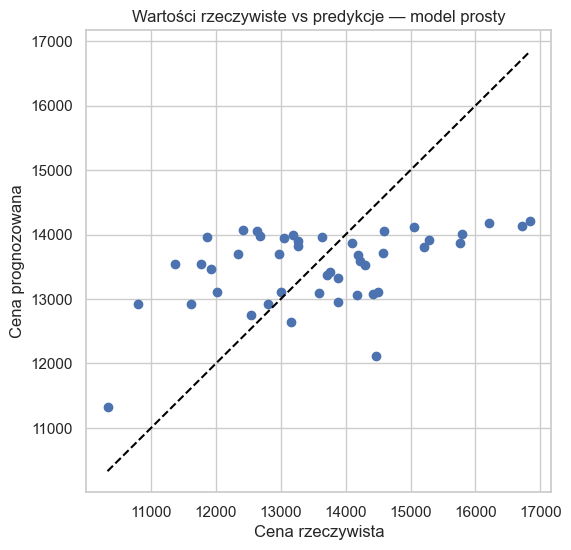

In [25]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_test)
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", color="black")
plt.title("Wartości rzeczywiste vs predykcje — model prosty")
plt.xlabel("Cena rzeczywista")
plt.ylabel("Cena prognozowana")
plt.show()

## Zadanie 5 — ocena predykcyjna

Odpowiedz:

1. Jaki jest błąd RMSE na zbiorze testowym?
2. Czy $R^2$ testowe jest zadowalające?
3. Czy model prosty ma sens jako model predykcyjny?
4. Jakie zmienne warto dodać?

**Odpowiedź — Zadanie 5:**  
1. RMSE na zbiorze testowym dla modelu prostego wynosi około $1317.35$.
2. Testowe $R^2\approx0.20$, czyli model wyjaśnia tylko około 20% zmienności ceny w danych testowych; to raczej niski wynik.
3. Model prosty ma sens jako punkt odniesienia i model interpretacyjny, ale predykcyjnie jest wyraźnie słabszy.
4. Warto dodać: `wiek_budynku`, `udogodnienia`, `powierzchnia_m2`, `pietro`, a także rozważyć nieliniowy efekt odległości.

# 8. Model wieloraki

Budujemy model:

$$
\text{cena\_m2} =
\beta_0
+ \beta_1 \cdot \text{wiek\_budynku}
+ \beta_2 \cdot \text{odleglosc\_centrum\_km}
+ \beta_3 \cdot \text{udogodnienia}
+ \beta_4 \cdot \text{powierzchnia\_m2}
+ \beta_5 \cdot \text{pietro}
+ \varepsilon
$$

In [12]:
model_2 = smf.ols(
    "cena_m2 ~ wiek_budynku + odleglosc_centrum_km + udogodnienia + powierzchnia_m2 + pietro",
    data=df
).fit()

model_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                cena_m2   R-squared:                       0.734
Model:                            OLS   Adj. R-squared:                  0.727
Method:                 Least Squares   F-statistic:                     96.23
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           3.19e-48
Time:                        15:07:04   Log-Likelihood:                -1457.8
No. Observations:                 180   AIC:                             2928.
Df Residuals:                     174   BIC:                             2947.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             1.365e+04    258.031     52.896      0.000    1.31e+04    1.42e+04
wiek_budynku           -43.4640      2.721    -15.974      0.000     -48.834     -38.094
odleglosc_centrum_km  -205.2857     21.307     -9.635      0.000    -247.340    -163.232
udogodnienia           486.5355     37.384     13.015      0.000     412.751     560.320
powierzchnia_m2         17.1205      3.280      5.220      0.000      10.647      23.594
pietro                  35.5061     17.326      2.049      0.042       1.309      69.703
==============================================================================
Omnibus:                        1.098   Durbin-Watson:                   2.066
Prob(Omnibus):                  0.577   Jarque-Bera (JB):                1.052
Skew:                           0.004   Prob(JB):                        0.591
Kurtosis:                       2.625   Cond. No.                         317.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [13]:
porownanie_statsmodels = pd.DataFrame({
    "model": ["model_1: tylko odległość", "model_2: wiele zmiennych"],
    "R2": [model_1.rsquared, model_2.rsquared],
    "R2_adj": [model_1.rsquared_adj, model_2.rsquared_adj],
    "AIC": [model_1.aic, model_2.aic],
    "BIC": [model_1.bic, model_2.bic]
})

porownanie_statsmodels

,model,R2,R2_adj,AIC,BIC
0,model_1: tylko odległość,0.100,0.095,3139.271,3145.657
1,model_2: wiele zmiennych,0.734,0.727,2927.568,2946.726


## Zadanie 6 — interpretacja modelu wielorakiego

Odpowiedz:

1. Które zmienne są statystycznie istotne?
2. Jak interpretujesz współczynnik przy `wiek_budynku`?
3. Jak interpretujesz współczynnik przy `udogodnienia`, przy założeniu stałości pozostałych zmiennych?
4. Czy model wieloraki jest lepszy od prostego według $R^2$, $R^2_{adj}$, AIC i BIC?

**Odpowiedź — Zadanie 6:**  
1. W modelu wielorakim **M2** statystycznie istotne są wszystkie zmienne ($p<0.05$), przy czym `pietro` jest istotne na granicy ($p\approx0.042$).
2. Współczynnik przy `wiek_budynku` wynosi około $-43.46$: przy stałych pozostałych cechach każdy dodatkowy rok wieku budynku obniża przeciętną cenę m² o około 43.5.
3. Współczynnik przy `udogodnienia` to około $+486.54$: dodatkowe jedno udogodnienie w okolicy podnosi przeciętną cenę m² o około 487, przy pozostałych zmiennych stałych.
4. Tak, model wieloraki jest wyraźnie lepszy od prostego: ma dużo wyższe $R^2$ i $R^2_{adj}$ oraz niższe AIC i BIC.

# 9. Transformacja cechy

Na wykresie EDA można zauważyć, że wpływ odległości od centrum niekoniecznie jest liniowy.  
Sprawdzimy transformację:

$$
\log(1 + \text{odleglosc\_centrum\_km})
$$

Taka transformacja oznacza, że pierwsze kilometry od centrum mogą mieć większy wpływ na cenę niż kolejne kilometry.

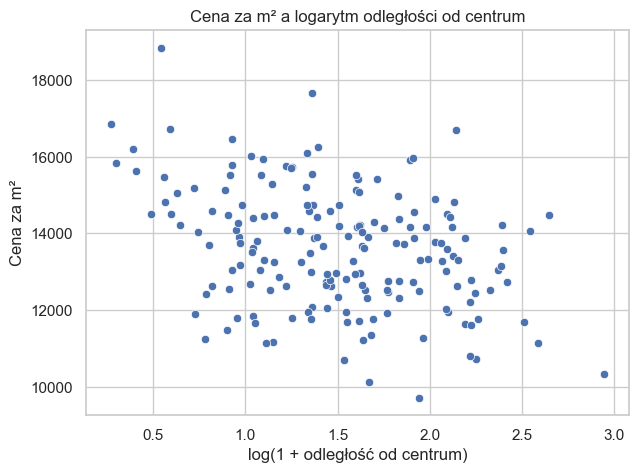

In [28]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="log_odleglosc", y="cena_m2")
plt.title("Cena za m² a logarytm odległości od centrum")
plt.xlabel("log(1 + odległość od centrum)")
plt.ylabel("Cena za m²")
plt.show()

In [14]:
model_3 = smf.ols(
    "cena_m2 ~ wiek_budynku + log_odleglosc + udogodnienia + powierzchnia_m2 + pietro",
    data=df
).fit()

model_3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                cena_m2   R-squared:                       0.745
Model:                            OLS   Adj. R-squared:                  0.738
Method:                 Least Squares   F-statistic:                     101.7
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           9.09e-50
Time:                        15:07:05   Log-Likelihood:                -1454.1
No. Observations:                 180   AIC:                             2920.
Df Residuals:                     174   BIC:                             2939.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        1.446e+04    286.278     50.526      0.000    1.39e+04     1.5e+04
wiek_budynku      -42.4870      2.663    -15.954      0.000     -47.743     -37.231
log_odleglosc   -1137.6473    111.537    -10.200      0.000   -1357.787    -917.507
udogodnienia      491.3018     36.650     13.405      0.000     418.967     563.637
powierzchnia_m2    16.9639      3.213      5.280      0.000      10.623      23.305
pietro             33.6377     16.971      1.982      0.049       0.143      67.132
==============================================================================
Omnibus:                        0.654   Durbin-Watson:                   2.026
Prob(Omnibus):                  0.721   Jarque-Bera (JB):                0.748
Skew:                          -0.006   Prob(JB):                        0.688
Kurtosis:                       2.684   Cond. No.                         367.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [15]:
porownanie_modeli = pd.DataFrame({
    "model": [
        "M1: tylko odległość",
        "M2: wiele zmiennych, odległość liniowo",
        "M3: wiele zmiennych, log(odległość)"
    ],
    "R2": [model_1.rsquared, model_2.rsquared, model_3.rsquared],
    "R2_adj": [model_1.rsquared_adj, model_2.rsquared_adj, model_3.rsquared_adj],
    "AIC": [model_1.aic, model_2.aic, model_3.aic],
    "BIC": [model_1.bic, model_2.bic, model_3.bic]
})

porownanie_modeli

,model,R2,R2_adj,AIC,BIC
0,M1: tylko odległość,0.100,0.095,3139.271,3145.657
1,"M2: wiele zmiennych, odległość liniowo",0.734,0.727,2927.568,2946.726
2,"M3: wiele zmiennych, log(odległość)",0.745,0.738,2920.161,2939.318


## Zadanie 7 — transformacja

Odpowiedz:

1. Czy transformacja logarytmiczna poprawiła model?
2. Który model ma najwyższe $R^2_{adj}$?
3. Który model ma najniższe AIC i BIC?
4. Czy poprawa jest duża, czy raczej umiarkowana?

**Odpowiedź — Zadanie 7:**  
1. Tak, transformacja logarytmiczna poprawiła model.
2. Najwyższe $R^2_{adj}$ ma model M3 (około $0.738$).
3. Najniższe AIC i BIC również ma model M3 (AIC około $2920.16$, BIC około $2939.32$).
4. Poprawa względem M2 jest umiarkowana, natomiast względem M1 jest bardzo duża.

# 10. Porównanie predykcyjne modeli

Porównamy trzy modele na zbiorze testowym:

1. model prosty: tylko odległość,
2. model wieloraki z odległością liniową,
3. model wieloraki z logarytmem odległości.

In [16]:
features_1 = ["odleglosc_centrum_km"]
features_2 = ["wiek_budynku", "odleglosc_centrum_km", "udogodnienia", "powierzchnia_m2", "pietro"]
features_3 = ["wiek_budynku", "log_odleglosc", "udogodnienia", "powierzchnia_m2", "pietro"]

X_train_1, X_test_1, y_train, y_test = train_test_split(
    df[features_1], df["cena_m2"], test_size=0.25, random_state=2026
)

X_train_2, X_test_2, _, _ = train_test_split(
    df[features_2], df["cena_m2"], test_size=0.25, random_state=2026
)

X_train_3, X_test_3, _, _ = train_test_split(
    df[features_3], df["cena_m2"], test_size=0.25, random_state=2026
)

modele_sklearn = {
    "M1: odległość": (X_train_1, X_test_1),
    "M2: wiele zmiennych": (X_train_2, X_test_2),
    "M3: wiele zmiennych + log": (X_train_3, X_test_3)
}

wyniki_predykcji = []

for nazwa, (Xtr, Xte) in modele_sklearn.items():
    model = LinearRegression()
    model.fit(Xtr, y_train)
    pred_train = model.predict(Xtr)
    pred_test = model.predict(Xte)

    wyniki_predykcji.append({
        "model": nazwa,
        "RMSE_train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_test)),
        "MAE_test": mean_absolute_error(y_test, pred_test),
        "R2_train": r2_score(y_train, pred_train),
        "R2_test": r2_score(y_test, pred_test)
    })

wyniki_predykcji = pd.DataFrame(wyniki_predykcji)
wyniki_predykcji

,model,RMSE_train,RMSE_test,MAE_test,R2_train,R2_test
0,M1: odległość,1512.526,1317.353,1127.029,0.070,0.200
1,M2: wiele zmiennych,821.532,730.827,590.430,0.726,0.754
2,M3: wiele zmiennych + log,809.587,707.647,575.626,0.733,0.769


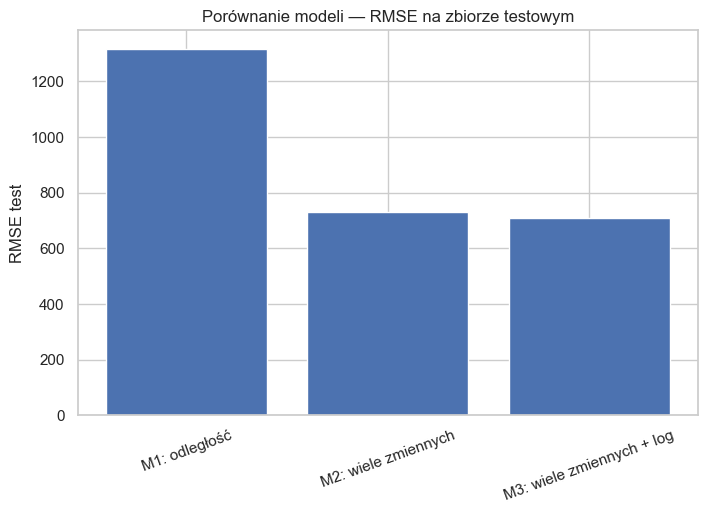

In [32]:
plt.figure(figsize=(8, 5))
plt.bar(wyniki_predykcji["model"], wyniki_predykcji["RMSE_test"])
plt.title("Porównanie modeli — RMSE na zbiorze testowym")
plt.xlabel("")
plt.ylabel("RMSE test")
plt.xticks(rotation=20)
plt.show()

## Zadanie 8 — wybór modelu

Wybierz najlepszy model i uzasadnij wybór.

Uwzględnij:

1. jakość dopasowania na danych treningowych,
2. jakość predykcji na danych testowych,
3. prostotę modelu,
4. możliwość interpretacji ekonomicznej,
5. diagnostykę reszt.

**Odpowiedź — Zadanie 8:**  
Najlepszym modelem jest **M3** czyli model wieloraki z logarytmem odległości.
Na treningu ma bardzo dobre dopasowanie ($R^2_{train}\approx0.733$), a na teście najlepszą jakość predykcyjną ($R^2_{test}\approx0.769$, najniższe RMSE i MAE).
W porównaniu z **M2** poprawa jest umiarkowana, ale stabilna.
Model **M1** jest najprostszy i czytelny interpretacyjnie, ale zdecydowanie przegrywa predykcyjnie.
Diagnostycznie dla modelu prostego nie ma silnych naruszeń normalności i homoskedastyczności, ale transformacja w **M3** lepiej oddaje nieliniowość zależności cena-odległość.
Rekomendacja praktyczna to **M3** do prognoz, natomiast **M1** możemy traktować jako model bazowy do szybkiej interpretacji.

# 11. Mini-raport końcowy

Na koniec przygotuj krótki raport, maksymalnie 10–12 zdań.

**Cel analizy:**  
Celem analizy było zbadanie, jak cechy mieszkania i lokalizacji wpływają na cenę za m² oraz wskazanie modelu najlepszego predykcyjnie.

**Dane:**  
Przeanalizowano 180 obserwacji z danymi o cenie m², powierzchni, wieku budynku, odległości od centrum, liczbie udogodnień i piętrze; brakowało braków danych.

**Model prosty:**  
Model z samą odległością pokazał istotny ujemny wpływ odległości ($\beta\approx-171.74$, $p<0.001$), ale niskie dopasowanie ($R^2\approx0.10$), więc nie jest wystarczający do dokładnej predykcji.

**Diagnostyka:**  
Średnia reszt była bliska zeru, test Shapiro-Wilka nie odrzucił normalności, a test Breuscha-Pagana nie wskazał istotnej heteroskedastyczności; zidentyfikowano kilka obserwacji o większym wpływie.

**Model wieloraki i transformacja:**  
Model wieloraki **M2** znacząco poprawił dopasowanie ($R^2_{adj}\approx0.727$), a po log-transformacji odległości **M3** uzyskano dalszą poprawę.
Wszystkie główne zmienne pozostały istotne statystycznie, a znaki współczynników były zgodne z intuicją ekonomiczną.

**Rekomendacja:**  
Do zastosowań predykcyjnych rekomendowany jest model **M3**, ponieważ osiąga najlepsze wyniki testowe, najniższe RMSE i najwyższe $R^2_{test}$.
Model prosty warto zachować jako punkt odniesienia interpretacyjnego, ale nie jako finalny model prognoz.

# Zadanie dodatkowe dla szybszych studentów

Wykonaj jedną z poniższych analiz:

## Wariant A — interakcja

Sprawdź model z interakcją:

$$
\text{cena\_m2} \sim \text{wiek\_budynku} + \text{log\_odleglosc} + \text{udogodnienia} + \text{powierzchnia\_m2} + \text{pietro} + \text{log\_odleglosc}:\text{udogodnienia}
$$

Czy wpływ odległości zależy od liczby udogodnień?

## Wariant B — regresja wielomianowa

Dodaj składnik:

$$
\text{odleglosc\_centrum\_km}^2
$$

i sprawdź, czy model poprawia się względem modelu liniowego.

## Wariant C — własny model

Zaproponuj własną specyfikację modelu i porównaj ją z modelami M1–M3.

In [17]:
# Miejsce na zadanie dodatkowe

# Przykład: model z interakcją
model_extra = smf.ols(
    "cena_m2 ~ wiek_budynku + log_odleglosc + udogodnienia + powierzchnia_m2 + pietro + log_odleglosc:udogodnienia",
    data=df
).fit()

model_extra.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                cena_m2   R-squared:                       0.746
Model:                            OLS   Adj. R-squared:                  0.737
Method:                 Least Squares   F-statistic:                     84.62
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           7.52e-49
Time:                        16:32:37   Log-Likelihood:                -1453.8
No. Observations:                 180   AIC:                             2922.
Df Residuals:                     173   BIC:                             2944.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
==============================================================================================
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept                   1.471e+04    447.020     32.904      0.000    1.38e+04    1.56e+04
wiek_budynku                 -42.7019      2.684    -15.910      0.000     -47.999     -37.404
log_odleglosc              -1302.1839    256.647     -5.074      0.000   -1808.746    -795.622
udogodnienia                 413.6443    115.068      3.595      0.000     186.527     640.762
powierzchnia_m2               16.8585      3.221      5.234      0.000      10.501      23.216
pietro                        35.3512     17.164      2.060      0.041       1.473      69.229
log_odleglosc:udogodnienia    52.8734     74.253      0.712      0.477     -93.684     199.431
==============================================================================
Omnibus:                        0.670   Durbin-Watson:                   2.027
Prob(Omnibus):                  0.715   Jarque-Bera (JB):                0.760
Skew:                           0.009   Prob(JB):                        0.684
Kurtosis:                       2.682   Cond. No.                         642.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [18]:
# Porównanie wariantu A (interakcja) z modelem M3
porownanie_extra = pd.DataFrame({
    "model": ["M3: bez interakcji", "M_extra: interakcja log_odleglosc:udogodnienia"],
    "R2": [model_3.rsquared, model_extra.rsquared],
    "R2_adj": [model_3.rsquared_adj, model_extra.rsquared_adj],
    "AIC": [model_3.aic, model_extra.aic],
    "BIC": [model_3.bic, model_extra.bic],
    "p_interakcja": [np.nan, model_extra.pvalues["log_odleglosc:udogodnienia"]]
})
porownanie_extra

,model,R2,R2_adj,AIC,BIC,p_interakcja
0,M3: bez interakcji,0.745,0.738,2920.161,2939.318,NaN
1,M_extra: interakcja log_odleglosc:udogodnienia,0.746,0.737,2921.634,2943.985,0.477


In [19]:
# Ocena predykcyjna M3 vs model z interakcją (ten sam podział train/test)
df_extra = df.copy()
df_extra["interakcja_log_udog"] = df_extra["log_odleglosc"] * df_extra["udogodnienia"]

features_extra = ["wiek_budynku", "log_odleglosc", "udogodnienia", "powierzchnia_m2", "pietro", "interakcja_log_udog"]

X_train_m3, X_test_m3, y_train_m3, y_test_m3 = train_test_split(
    df[features_3], df["cena_m2"], test_size=0.25, random_state=2026
)
X_train_extra, X_test_extra, y_train_extra, y_test_extra = train_test_split(
    df_extra[features_extra], df_extra["cena_m2"], test_size=0.25, random_state=2026
)

lr_m3 = LinearRegression().fit(X_train_m3, y_train_m3)
lr_extra = LinearRegression().fit(X_train_extra, y_train_extra)

pred_m3_test = lr_m3.predict(X_test_m3)
pred_extra_test = lr_extra.predict(X_test_extra)

porownanie_pred_extra = pd.DataFrame({
    "model": ["M3", "M_extra_interakcja"],
    "RMSE_test": [
        np.sqrt(mean_squared_error(y_test_m3, pred_m3_test)),
        np.sqrt(mean_squared_error(y_test_extra, pred_extra_test))
    ],
    "MAE_test": [
        mean_absolute_error(y_test_m3, pred_m3_test),
        mean_absolute_error(y_test_extra, pred_extra_test)
    ],
    "R2_test": [
        r2_score(y_test_m3, pred_m3_test),
        r2_score(y_test_extra, pred_extra_test)
    ]
})
porownanie_pred_extra

,model,RMSE_test,MAE_test,R2_test
0,M3,707.647,575.626,0.769
1,M_extra_interakcja,704.665,570.694,0.771
